In [32]:
import seaborn as sns

sns.set_theme(
    context="paper", style="ticks", rc={"axes.spines.top": False, "axes.spines.right": False}
)

# **`numpy` : programmation orientée tableau** 

- Le module `numpy` est l'outil de base utilisé dans tous calculs scientifiques et donc numériques en Python.
- `numpy` fournit essentiellement des objets de type **vecteurs, matrices en généralisant la notion de tableaux à $n$ dimensions $\to$ `ndarray`**.
- `numpy` facilite et **optimise** les opérations de **stockage et de manipulation** des données **numériques** notamment lorsque la taille des tableaux devient importante $\to$ *array oriented computing*.

## **Installation & importation de `numpy`**

```sh
pip install numpy
```

In [4]:
import numpy as np

np.__version__

'2.5.4'

La documentation, en ligne, du module se trouve à l'adresse suivante https://numpy.org/doc. Indépendamment d'une connexion internet, on peut toujours interroger l'aide interactive à l'aide de la fonction `help` ou de l'opérateur `?` de `ipython`.

In [5]:
np.array?

Signature:
np.array(
    object,
    dtype=None,
    *,
    copy=True,
    order='K',
    subok=False,
    ndmin=0,
    ndmax=0,
    like=None,
)
Docstring:
array(object, dtype=None, *, copy=True, order='K', subok=False, ndmin=0,
      ndmax=0, like=None)

Create an array.

Parameters
----------
object : array_like
    An array, any object exposing the array interface, an object whose
    ``__array__`` method returns an array, or any (nested) sequence.
    If object is a scalar, a 0-dimensional array containing object is
    returned.
dtype : data-type, optional
    The desired data-type for the array. If not given, NumPy will try to use
    a default ``dtype`` that can represent the values (by applying promotion
    rules when necessary.)
copy : bool, optional
    If ``True`` (default), then the array data is copied. If ``None``,
    a copy will only be made if ``__array__`` returns a copy, if obj is
    a nested sequence, or if a copy is needed to satisfy any of the other
    require

## **Création de vecteurs, matrices**

Un tableau `numpy` peut être créé à partir d'une liste de valeurs

In [7]:
v = np.array([0, 1, 2, 3])
v

array([0, 1, 2, 3])

Pour une matrice

In [8]:
m = np.array([[0, 1], [2, 3]])
m

array([[0, 1],
       [2, 3]])

In [9]:
type(v), type(m)

(numpy.ndarray, numpy.ndarray)

In [10]:
v.ndim, m.ndim

(1, 2)

In [11]:
v.shape, m.shape

((4,), (2, 2))

À travers les deux exemples ci-dessus, rien ne semble différencier un objet de type `list` d'un tableau `numpy` si ce n'est le type : **pourquoi ne pas simplement utiliser les listes Python pour les calculs au lieu de créer un nouveau type de tableau ?**

Il existe plusieurs (très bonnes) raisons à cela :
- Les listes Python sont très générales (on parle également d'objet de haut niveau). **Elles peuvent contenir n'importe quel objet grâce au typage dynamique**.
- Du fait de cette hétérogénéité, les listes ne supportent pas les opérations mathématiques.
- Les tableaux `numpy` sont **statiquement typées et homogène** (pour plus de détails, *cf.* [discussion](https://jakevdp.github.io/PythonDataScienceHandbook/02.01-understanding-data-types.html)).
  - Le type des éléments est déterminé lorsque le tableau est créé **$\to$ plus de typage dynamique**.
  - De même la taille du tableau est fixée à la création **$\to$ stockage en mémoire optimisé**.
- En raison du typage statique, les opérations mathématiques peuvent être mises en œuvre *via* un langage compilé (C et Fortran).

Une fois les tableaux `numpy` déclarés, les opérations mathématiques sont grandement optimisées et le gain en temps est significatif : en moyenne, le temps nécessaire à la création d'une liste contenant le carré des milles premiers entiers prend

In [12]:
%timeit [i**2 for i in range(1000)]

86.5 μs ± 26.8 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


alors que la même opération à l'aide d'un tableau `numpy` prendra

In [13]:
%timeit np.arange(1000)**2

1.94 μs ± 138 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## **Création de tableau `numpy` (suite)**

Le type de données numériques est défini à la création du tableau et ne peut plus être modifié sans créer un nouvel objet en mémoire

In [14]:
v = np.array([0, 1, 2, 3])
v.dtype

dtype('int64')

In [15]:
v = np.array([0.0, 1.0, 2.0, 3.0])
v.dtype

dtype('float64')

On peut cependant forcer le type de données lors de la création du tableau

In [16]:
v = np.array([0, 1, 2, 3], dtype=float)
v.dtype

dtype('float64')

Dans la pratique, les valeurs d'un tableau sont rarement saisies une par une et `numpy` fournit un ensemble de fonctions afin de créer des tableaux. La fonction `np.arange` permet de créer un tableau à l'image de la fonction `range` de Python

In [17]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [18]:
np.arange(0, 10, 2)

array([0, 2, 4, 6, 8])

In [19]:
np.arange(0, 1, step=0.1)

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

On peut également créer des tableaux dont les éléments sont linéairement/logarithmiquement espacés

In [20]:
np.linspace(0, 10, num=5)

array([ 0. ,  2.5,  5. ,  7.5, 10. ])

In [21]:
np.logspace(0, 10, num=5)

array([1.00000000e+00, 3.16227766e+02, 1.00000000e+05, 3.16227766e+07,
       1.00000000e+10])

Il est également possible de créer des tableaux pré-remplis de valeurs

In [22]:
np.zeros(10)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [23]:
np.ones(shape=(3, 3))

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [24]:
np.full(shape=(3, 3), fill_value=666.666, dtype=int)

array([[666, 666, 666],
       [666, 666, 666],
       [666, 666, 666]])

In [25]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [26]:
np.diag([0, 1, 2, 3])

array([[0, 0, 0, 0],
       [0, 1, 0, 0],
       [0, 0, 2, 0],
       [0, 0, 0, 3]])

Il est finalement possible de générer des valeurs aléatoires à l'aide du module `np.random`. Pour créer un tableau de valeurs aléatoirement réparties entre 0 et 1

In [27]:
np.random.rand(3)

array([0.00456701, 0.14501101, 0.56943816])

ou des valeurs entières

In [28]:
np.random.randint(0, 10, 3)

array([0, 0, 8])

Pour générer des valeurs selon une loi normale centrée sur 0 et d'écart-type 1

In [29]:
np.random.randn(3)

array([1.21129798, 1.32201393, 0.4851039 ])

> Un générateur aléatoire n'est, par définition, pas aléatoire dans une machine déterministe qu'est un ordinateur ! Pour fixer la graine du générateur aléatoire on utilisera `np.random.seed(1234)`.

### **&nbsp;*Intermède graphique* : génération d'une carte de bruit gaussien**

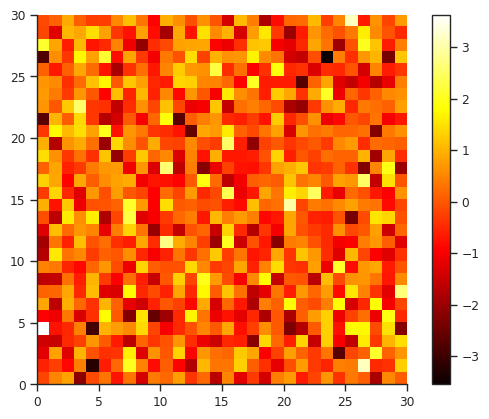

In [33]:
import matplotlib.pyplot as plt
import numpy as np

img = np.random.randn(30, 30)
plt.imshow(img, cmap=plt.cm.hot, extent=(0, 30, 0, 30))
plt.colorbar();

## **Parcours & sélection par indice**

Tout comme les listes, les éléments d'un tableau `numpy` peuvent être sélectionnés par indice à l'aide de l'opérateur `[]`

In [35]:
x = np.random.randint(10, size=5)
x

array([9, 3, 4, 1, 9])

In [36]:
x[0], x[3], x[-1]

(np.int64(9), np.int64(1), np.int64(9))

Pour les tableaux à $n$ dimensions

In [37]:
x = np.random.randint(10, size=(3, 4))
x

array([[0, 4, 1, 1],
       [4, 6, 9, 7],
       [3, 7, 1, 2]])

In [38]:
x[0, 0], x[2, -1]

(np.int64(0), np.int64(2))

Les tableaux `numpy` sont également des objets *mutables* à savoir que leur contenu peut être modifié

In [39]:
x[0, 0] = 12
x

array([[12,  4,  1,  1],
       [ 4,  6,  9,  7],
       [ 3,  7,  1,  2]])

En revanche, il faut bien se souvenir que le type de données numériques stockées est fixé à la création du tableau. Dans l'exemple ci-dessus, les données sont des nombres entiers et assigner une valeur flottante conduira à la troncation de la partie décimale

In [40]:
x[0, 0] = 3.1415
x

array([[3, 4, 1, 1],
       [4, 6, 9, 7],
       [3, 7, 1, 2]])

De même que pour les listes, il est possible d'utiliser la syntaxe `[start:stop:step]` pour sélectionner un sous espace vectoriel. Pour sélectionner une ligne dans la matrice `x` précédente, on fera

In [41]:
x[0]

array([3, 4, 1, 1])

Pour sélectionner une colonne

In [42]:
x[:, 0]

array([3, 4, 3])

In [43]:
x[:, -1]

array([1, 7, 2])

Il est finalement possible de fournir une liste d'indices

In [44]:
x = np.random.randint(0, 10, (3, 3))
x

array([[2, 6, 0],
       [7, 7, 8],
       [6, 8, 3]])

In [45]:
x[(1, 2), (0, 2)]

array([7, 3])

*Exemple :* manipulation des valeurs de la diagonale d'une matrice

In [46]:
i = list(range(3))
x[i, i] = 666
x

array([[666,   6,   0],
       [  7, 666,   8],
       [  6,   8, 666]])

> La fonction `np.diag_indices` retourne les couples de valeurs d'indices correspondant à la diagonale d'une matrice carrée tandis que la fonction `np.diag` extrait la diagonale.

À la différence des listes, les sous espaces vectoriels sélectionnés ne sont pas des copies mais **une vue réduite** de la matrice globale. Toute modification opérée sur le sous espace vectoriel est reportée dans la matrice globale.

In [47]:
x

array([[666,   6,   0],
       [  7, 666,   8],
       [  6,   8, 666]])

In [49]:
xx = x[:2, :2]
xx

array([[666,   6],
       [  7, 666]])

In [51]:
xx[0, 0] = 0
xx

array([[  0,   6],
       [  7, 666]])

In [52]:
x

array([[  0,   6,   0],
       [  7, 666,   8],
       [  6,   8, 666]])

Pour réaliser une copie d'un sous espace vectoriel, on utilisera la méthode `copy()`

In [53]:
xx = x[:2, :2].copy()
xx[0, 0] = 1234
xx

array([[1234,    6],
       [   7,  666]])

In [54]:
x

array([[  0,   6,   0],
       [  7, 666,   8],
       [  6,   8, 666]])

## **Opérations mathématiques**

Pour rappel, avec des listes, il est impossible de réaliser des opérations mathématiques quand bien même le contenu de la liste serait homogène

In [55]:
v = [1, 2, 3, 4]
v + 5

TypeError: can only concatenate list (not "int") to list

Pour réaliser une opération mathématique avec des listes, il faudra donc en passer par une boucle `for` beaucoup plus coûteuse en temps. **Grâce à l'homogénéité des tableaux de `numpy`**, il est possible de réaliser des opérations mathématiques

In [56]:
v = np.array([1, 2, 3, 4])
v + 5

array([6, 7, 8, 9])

On retrouve ainsi les opérations binaires

In [57]:
x = np.arange(4)

x + 5

array([5, 6, 7, 8])

In [58]:
x - 5

array([-5, -4, -3, -2])

In [59]:
x * 5

array([ 0,  5, 10, 15])

In [60]:
x / 5

array([0. , 0.2, 0.4, 0.6])

De même, nous avons les opérations unaires `+=`, `-=`, `*=`, `/=`

In [63]:
x += 5
x

array([5, 6, 7, 8])

In [64]:
-x

array([-5, -6, -7, -8])

In [65]:
x**2

array([25, 36, 49, 64])

In [66]:
x % 2

array([1, 0, 1, 0])

En plus des opérateurs usuels, `numpy` fournit un ensemble de **fonctions dites universelles** (ou *ufuncs*) opérant sur des tableaux parmi lesquelles les fonctions trigonométriques

In [67]:
theta = np.linspace(0, np.pi, 3)

np.cos(theta)

array([ 1.000000e+00,  6.123234e-17, -1.000000e+00])

In [68]:
np.sin(theta)

array([0.0000000e+00, 1.0000000e+00, 1.2246468e-16])

In [69]:
np.tan(theta)

array([ 0.00000000e+00,  1.63312394e+16, -1.22464680e-16])

Autres fonctions : `np.exp`, `np.power`, `np.log`, `np.log10`, ...

### ***Intermède graphique***

In [70]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(-5, 5, 0.5)

y1 = x**2 + x + 1.0
y1

array([21.  , 16.75, 13.  ,  9.75,  7.  ,  4.75,  3.  ,  1.75,  1.  ,
        0.75,  1.  ,  1.75,  3.  ,  4.75,  7.  ,  9.75, 13.  , 16.75,
       21.  , 25.75])

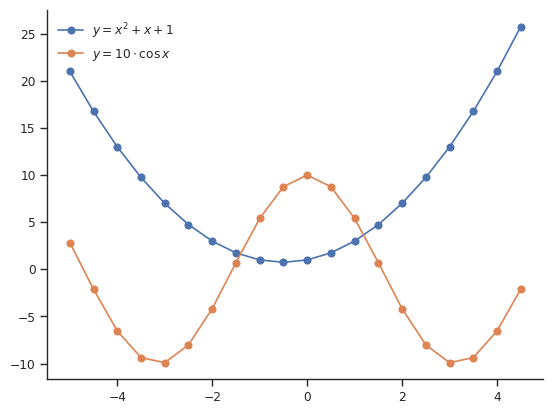

In [79]:
y2 = 10 * np.cos(x)
plt.plot(x, y1, "-o", label=r"$y = x^2+x+1$")
plt.plot(x, y2, "-o", label=r"$y = 10\cdot\cos x$")
plt.legend();

## **Opérations statistiques**

À l'image des opérations arithmétiques et des fonctions mathématiques, `numpy` implémente un grand nombre d'opérations statistiques (calcul de moyenne, écart-type, ...). Pour rappel, Python fournit quelques fonctions intégrées telle que `sum` pour calculer la somme des éléments de tout objet *itérable*

In [80]:
x = np.random.rand(100)

sum(x)

np.float64(47.80194793054275)

In [85]:
np.sum(x)

np.float64(47.80194793054275)

Toutefois, la formulation `np.sum` propre à `numpy` présente l'avantage d'être nettement plus rapide (code compilé)

In [83]:
big_array = np.random.rand(1_000_000)

%timeit sum(big_array)

94.2 ms ± 9.33 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [84]:
%timeit np.sum(big_array)

604 μs ± 29.8 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


L'implémentation de `np.sum` est, comme pour la majorité des opérations statistiques implémentées par `numpy`, beaucoup plus générale. Il est ainsi possible de calculer la somme sur l'ensemble des éléments d'un tableau `numpy` 

In [86]:
m = np.random.randint(10, size=(3, 4))
m

array([[0, 3, 4, 4],
       [7, 0, 6, 2],
       [4, 0, 3, 8]])

In [87]:
np.sum(m), m.sum()

(np.int64(41), np.int64(41))

mais aussi de calculer la somme par colonne

In [88]:
np.sum(m, axis=0)

array([11,  3, 13, 14])

ou par ligne

In [90]:
np.sum(m, axis=1)

array([11, 15, 15])

Les principales fonctions sont répertoriées dans le tableau ci-dessous

| Fonction        | Description                      |
|:----------------|:---------------------------------|
| `np.sum`        | Somme des éléments               |
| `np.prod`       | Produit des éléments             |
| `np.mean`       | Valeur moyenne                   |
| `np.std`        | Déviation standard ou écart-type |
| `np.var`        | Variance                         |
| `np.min`        | Valeur minimale                  |
| `np.max`        | Valeur maximale                  |
| `np.argmin`     | Indice de la valeur minimale     |
| `np.argmax`     | Indice de la valeur maximale     |
| `np.median`     | Valeur médiane                   |
| `np.percentile` | Quantiles                        |


## **Opérations algébriques**

`numpy` fournit également des fonctions/opérateurs pour le calcul algébrique. On peut ainsi transposer une matrice

In [91]:
m = np.random.randint(5, size=(3, 3))
m

array([[2, 4, 4],
       [3, 4, 2],
       [0, 4, 1]])

In [92]:
m.transpose()

array([[2, 3, 0],
       [4, 4, 4],
       [4, 2, 1]])

Toutefois, cette opération ne "fonctionne" pas pour transformer un vecteur de $n$ éléments en une matrice 1 colonne, $n$ lignes

In [93]:
v = np.arange(4)
v.transpose()

array([0, 1, 2, 3])

Pour réaliser cette opération, on pourra procéder de la façon suivante

In [96]:
v[:, np.newaxis]  # ou v[:, None]

array([[0],
       [1],
       [2],
       [3]])

ou à l'aide de la fonction `reshape`

In [95]:
v.reshape(4, 1)

array([[0],
       [1],
       [2],
       [3]])

### ***Intermède graphique***

  \begin{align*}
    z = f(x,y) =& \sin^{10} x + \cos(x\cdot y)\cdot\cos x\\
    =&\sin^{10}\begin{bmatrix}
    x_0&\cdots
    \end{bmatrix}+\cos\left(\begin{bmatrix}
        x_0&\cdots
      \end{bmatrix}\cdot\begin{bmatrix}
    y_0\\\vdots\end{bmatrix}\right)\cdot\cos\begin{bmatrix}
        x_0&\cdots
      \end{bmatrix}
  \end{align*}


In [97]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 5, 500)
y = np.linspace(0, 5, 500)[:, np.newaxis]
z = np.sin(x) ** 10 + np.cos(x * y) * np.cos(x)
x.shape, y.shape, z.shape

((500,), (500, 1), (500, 500))

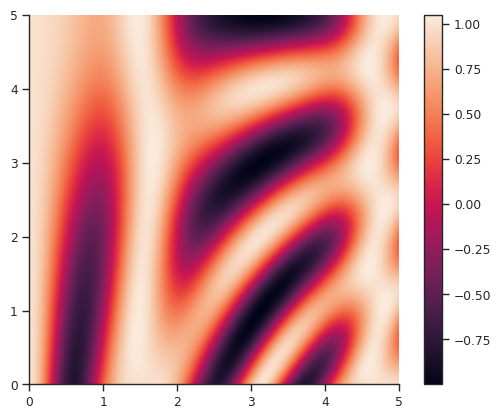

In [98]:
plt.imshow(z, extent=[0, 5, 0, 5])
plt.colorbar();

Un point de vigilance tient au produit matriciel sachant que l'opérateur `*` est réservé à la multiplication élément par élément. Pour réaliser un produit matriciel, on utilisera la fonction `np.dot` ou l'opérateur `@`

In [99]:
m = np.ones(shape=(3, 3))
m

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [100]:
m * m

array([[1., 1., 1.],
       [1., 1., 1.],
       [1., 1., 1.]])

In [101]:
m.dot(m)

array([[3., 3., 3.],
       [3., 3., 3.],
       [3., 3., 3.]])

In [102]:
m @ m

array([[3., 3., 3.],
       [3., 3., 3.],
       [3., 3., 3.]])

## **Opérations logiques**

En plus des opérateurs et fonctions mathématiques, `numpy` fournit finalement les opérateurs de comparaison opérant sur les éléments d'un tableau

In [105]:
x = np.arange(6)
x

array([0, 1, 2, 3, 4, 5])

In [106]:
x < 3

array([ True,  True,  True, False, False, False])

In [107]:
x == 3

array([False, False, False,  True, False, False])

In [108]:
(x * 2) == (x**2)

array([ True, False,  True, False, False, False])

Les fonctions `any` et `all` permettent de vérifier l'existence, au sein d'un tableau de booléens, d'au moins un élément vrai (`any`) ou que la totalité du tableau contient des valeurs vraies (`all`)

In [109]:
np.any(x > 10)

np.False_

In [110]:
np.all(x < 10)

np.True_

Il est finalement possible de dénombrer le nombre de valeurs d'un tableau satisfaisant à une ou des conditions

In [111]:
np.sum(x > 3)

np.int64(2)

In [112]:
np.sum((x > 3) & (x < 5))

np.int64(1)

> Il n'est pas possible d'utiliser les opérateurs `or`, `and` ou `not`. Ces opérateurs sont respectivement remplacés par `|`, `&` et `~` (*bit logic*)

## **Sélection par masque**

Les opérations de comparaison sur des tableaux retournent un tableau de booléens qui peut servir à la sélection d'éléments du tableau

In [113]:
x = np.random.randint(0, 10, 10)
x

array([5, 3, 1, 4, 4, 9, 1, 1, 1, 3])

In [114]:
x < 5

array([False,  True,  True,  True,  True, False,  True,  True,  True,
        True])

In [115]:
x[x < 5]

array([3, 1, 4, 4, 1, 1, 1, 3])

In [116]:
x[x < 5] = -1
x

array([ 5, -1, -1, -1, -1,  9, -1, -1, -1, -1])

### ***Intermède graphique***

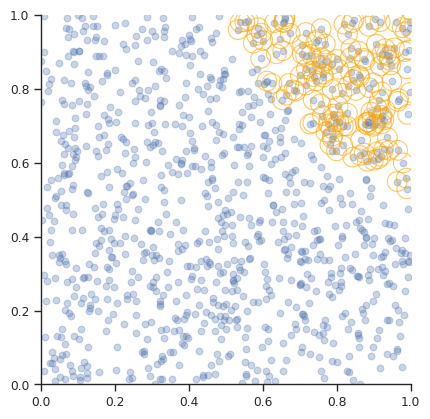

In [117]:
import matplotlib.pyplot as plt
import numpy as np

x = np.random.rand(1000)
y = np.random.rand(1000)
plt.scatter(x, y, alpha=0.3)
plt.axis("scaled")
plt.axis([0, 1, 0, 1])

mask = x * y > 0.5
plt.scatter(x[mask], y[mask], alpha=0.6, edgecolors="orange", c="none", s=200);

## **Entrées/sorties de `numpy`**

`numpy` permet de charger un fichier texte dans un objet de type `np.ndarray`

In [121]:
%%bash
cat <<EOF > /tmp/results.tsv
# id        OPP    MQ1     MA
21606456   9.90  12.32  16.00
21402354  11.20  10.50  12.25
EOF

In [122]:
!cat /tmp/results.tsv

# id        OPP    MQ1     MA
21606456   9.90  12.32  16.00
21402354  11.20  10.50  12.25


In [123]:
results = np.loadtxt("/tmp/results.tsv")
results

array([[2.1606456e+07, 9.9000000e+00, 1.2320000e+01, 1.6000000e+01],
       [2.1402354e+07, 1.1200000e+01, 1.0500000e+01, 1.2250000e+01]])

**Le module [`pandas`](http://pandas.pydata.org) est toutefois bien mieux adapté à la lecture/écriture de fichier contenant des données numériques**

## **Annexes**

### ***Broadcasting***

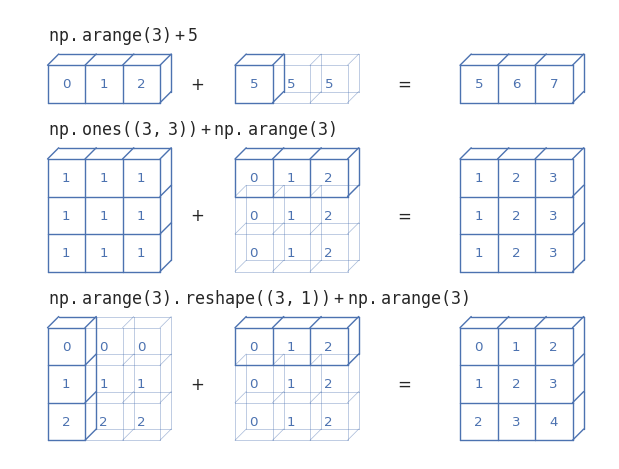

In [141]:
# Adapted from astroML: see http://www.astroml.org/book_figures/appendix/fig_broadcast_visual.html
import numpy as np
from matplotlib import pyplot as plt

# ------------------------------------------------------------
# Draw a figure and axis with no boundary
fig = plt.figure(figsize=(6, 4.5), facecolor="w")
ax = plt.axes([0, 0, 1, 1], xticks=[], yticks=[], frameon=False)


def draw_cube(ax, xy, size, depth=0.4, edges=None, label=None, label_kwargs=None, **kwargs):
    """draw and label a cube.  edges is a list of numbers between
    1 and 12, specifying which of the 12 cube edges to draw"""
    if edges is None:
        edges = range(1, 13)

    x, y = xy

    if 1 in edges:
        ax.plot([x, x + size], [y + size, y + size], **kwargs)
    if 2 in edges:
        ax.plot([x + size, x + size], [y, y + size], **kwargs)
    if 3 in edges:
        ax.plot([x, x + size], [y, y], **kwargs)
    if 4 in edges:
        ax.plot([x, x], [y, y + size], **kwargs)

    if 5 in edges:
        ax.plot([x, x + depth], [y + size, y + depth + size], **kwargs)
    if 6 in edges:
        ax.plot([x + size, x + size + depth], [y + size, y + depth + size], **kwargs)
    if 7 in edges:
        ax.plot([x + size, x + size + depth], [y, y + depth], **kwargs)
    if 8 in edges:
        ax.plot([x, x + depth], [y, y + depth], **kwargs)

    if 9 in edges:
        ax.plot([x + depth, x + depth + size], [y + depth + size, y + depth + size], **kwargs)
    if 10 in edges:
        ax.plot([x + depth + size, x + depth + size], [y + depth, y + depth + size], **kwargs)
    if 11 in edges:
        ax.plot([x + depth, x + depth + size], [y + depth, y + depth], **kwargs)
    if 12 in edges:
        ax.plot([x + depth, x + depth], [y + depth, y + depth + size], **kwargs)

    if label:
        if label_kwargs is None:
            label_kwargs = {}
        ax.text(x + 0.5 * size, y + 0.5 * size, label, ha="center", va="center", **label_kwargs)

color = "#4c72b0"
solid = dict(c=color, ls="-", lw=1, label_kwargs=dict(color=color))
dotted = solid | dict(lw=0.5, alpha=0.5)
depth = 0.3

# ------------------------------------------------------------
# Draw top operation: vector plus scalar
draw_cube(ax, (1, 10), 1, depth, [1, 2, 3, 4, 5, 6, 9], "0", **solid)
draw_cube(ax, (2, 10), 1, depth, [1, 2, 3, 6, 9], "1", **solid)
draw_cube(ax, (3, 10), 1, depth, [1, 2, 3, 6, 7, 9, 10], "2", **solid)

draw_cube(ax, (6, 10), 1, depth, [1, 2, 3, 4, 5, 6, 7, 9, 10], "5", **solid)
draw_cube(ax, (7, 10), 1, depth, [1, 2, 3, 6, 7, 9, 10, 11], "5", **dotted)
draw_cube(ax, (8, 10), 1, depth, [1, 2, 3, 6, 7, 9, 10, 11], "5", **dotted)

draw_cube(ax, (12, 10), 1, depth, [1, 2, 3, 4, 5, 6, 9], "5", **solid)
draw_cube(ax, (13, 10), 1, depth, [1, 2, 3, 6, 9], "6", **solid)
draw_cube(ax, (14, 10), 1, depth, [1, 2, 3, 6, 7, 9, 10], "7", **solid)

ax.text(5, 10.5, "+", size=12, ha="center", va="center")
ax.text(10.5, 10.5, "=", size=12, ha="center", va="center")
ax.text(1, 11.5, r"${\tt np.arange(3) + 5}$", size=12, ha="left", va="bottom")

# ------------------------------------------------------------
# Draw middle operation: matrix plus vector

# first block
draw_cube(ax, (1, 7.5), 1, depth, [1, 2, 3, 4, 5, 6, 9], "1", **solid)
draw_cube(ax, (2, 7.5), 1, depth, [1, 2, 3, 6, 9], "1", **solid)
draw_cube(ax, (3, 7.5), 1, depth, [1, 2, 3, 6, 7, 9, 10], "1", **solid)

draw_cube(ax, (1, 6.5), 1, depth, [2, 3, 4], "1", **solid)
draw_cube(ax, (2, 6.5), 1, depth, [2, 3], "1", **solid)
draw_cube(ax, (3, 6.5), 1, depth, [2, 3, 7, 10], "1", **solid)

draw_cube(ax, (1, 5.5), 1, depth, [2, 3, 4], "1", **solid)
draw_cube(ax, (2, 5.5), 1, depth, [2, 3], "1", **solid)
draw_cube(ax, (3, 5.5), 1, depth, [2, 3, 7, 10], "1", **solid)

# second block
draw_cube(ax, (6, 7.5), 1, depth, [1, 2, 3, 4, 5, 6, 9], "0", **solid)
draw_cube(ax, (7, 7.5), 1, depth, [1, 2, 3, 6, 9], "1", **solid)
draw_cube(ax, (8, 7.5), 1, depth, [1, 2, 3, 6, 7, 9, 10], "2", **solid)

draw_cube(ax, (6, 6.5), 1, depth, range(2, 13), "0", **dotted)
draw_cube(ax, (7, 6.5), 1, depth, [2, 3, 6, 7, 9, 10, 11], "1", **dotted)
draw_cube(ax, (8, 6.5), 1, depth, [2, 3, 6, 7, 9, 10, 11], "2", **dotted)

draw_cube(ax, (6, 5.5), 1, depth, [2, 3, 4, 7, 8, 10, 11, 12], "0", **dotted)
draw_cube(ax, (7, 5.5), 1, depth, [2, 3, 7, 10, 11], "1", **dotted)
draw_cube(ax, (8, 5.5), 1, depth, [2, 3, 7, 10, 11], "2", **dotted)

# third block
draw_cube(ax, (12, 7.5), 1, depth, [1, 2, 3, 4, 5, 6, 9], "1", **solid)
draw_cube(ax, (13, 7.5), 1, depth, [1, 2, 3, 6, 9], "2", **solid)
draw_cube(ax, (14, 7.5), 1, depth, [1, 2, 3, 6, 7, 9, 10], "3", **solid)

draw_cube(ax, (12, 6.5), 1, depth, [2, 3, 4], "1", **solid)
draw_cube(ax, (13, 6.5), 1, depth, [2, 3], "2", **solid)
draw_cube(ax, (14, 6.5), 1, depth, [2, 3, 7, 10], "3", **solid)

draw_cube(ax, (12, 5.5), 1, depth, [2, 3, 4], "1", **solid)
draw_cube(ax, (13, 5.5), 1, depth, [2, 3], "2", **solid)
draw_cube(ax, (14, 5.5), 1, depth, [2, 3, 7, 10], "3", **solid)

ax.text(5, 7.0, "+", size=12, ha="center", va="center")
ax.text(10.5, 7.0, "=", size=12, ha="center", va="center")
ax.text(1, 9.0, r"${\tt np.ones((3,\, 3)) + np.arange(3)}$", size=12, ha="left", va="bottom")

# ------------------------------------------------------------
# Draw bottom operation: vector plus vector, double broadcast

# first block
draw_cube(ax, (1, 3), 1, depth, [1, 2, 3, 4, 5, 6, 7, 9, 10], "0", **solid)
draw_cube(ax, (1, 2), 1, depth, [2, 3, 4, 7, 10], "1", **solid)
draw_cube(ax, (1, 1), 1, depth, [2, 3, 4, 7, 10], "2", **solid)

draw_cube(ax, (2, 3), 1, depth, [1, 2, 3, 6, 7, 9, 10, 11], "0", **dotted)
draw_cube(ax, (2, 2), 1, depth, [2, 3, 7, 10, 11], "1", **dotted)
draw_cube(ax, (2, 1), 1, depth, [2, 3, 7, 10, 11], "2", **dotted)

draw_cube(ax, (3, 3), 1, depth, [1, 2, 3, 6, 7, 9, 10, 11], "0", **dotted)
draw_cube(ax, (3, 2), 1, depth, [2, 3, 7, 10, 11], "1", **dotted)
draw_cube(ax, (3, 1), 1, depth, [2, 3, 7, 10, 11], "2", **dotted)

# second block
draw_cube(ax, (6, 3), 1, depth, [1, 2, 3, 4, 5, 6, 9], "0", **solid)
draw_cube(ax, (7, 3), 1, depth, [1, 2, 3, 6, 9], "1", **solid)
draw_cube(ax, (8, 3), 1, depth, [1, 2, 3, 6, 7, 9, 10], "2", **solid)

draw_cube(ax, (6, 2), 1, depth, range(2, 13), "0", **dotted)
draw_cube(ax, (7, 2), 1, depth, [2, 3, 6, 7, 9, 10, 11], "1", **dotted)
draw_cube(ax, (8, 2), 1, depth, [2, 3, 6, 7, 9, 10, 11], "2", **dotted)

draw_cube(ax, (6, 1), 1, depth, [2, 3, 4, 7, 8, 10, 11, 12], "0", **dotted)
draw_cube(ax, (7, 1), 1, depth, [2, 3, 7, 10, 11], "1", **dotted)
draw_cube(ax, (8, 1), 1, depth, [2, 3, 7, 10, 11], "2", **dotted)

# third block
draw_cube(ax, (12, 3), 1, depth, [1, 2, 3, 4, 5, 6, 9], "0", **solid)
draw_cube(ax, (13, 3), 1, depth, [1, 2, 3, 6, 9], "1", **solid)
draw_cube(ax, (14, 3), 1, depth, [1, 2, 3, 6, 7, 9, 10], "2", **solid)

draw_cube(ax, (12, 2), 1, depth, [2, 3, 4], "1", **solid)
draw_cube(ax, (13, 2), 1, depth, [2, 3], "2", **solid)
draw_cube(ax, (14, 2), 1, depth, [2, 3, 7, 10], "3", **solid)

draw_cube(ax, (12, 1), 1, depth, [2, 3, 4], "2", **solid)
draw_cube(ax, (13, 1), 1, depth, [2, 3], "3", **solid)
draw_cube(ax, (14, 1), 1, depth, [2, 3, 7, 10], "4", **solid)

ax.text(5, 2.5, "+", size=12, ha="center", va="center")
ax.text(10.5, 2.5, "=", size=12, ha="center", va="center")
ax.text(
    1,
    4.5,
    r"${\tt np.arange(3).reshape((3,\, 1)) + np.arange(3)}$",
    ha="left",
    size=12,
    va="bottom",
)

ax.set_xlim(0, 16)
ax.set_ylim(0.5, 12.5);

Pour plus de détails, *cf.* [discussion](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html)

### **Opérations diverses : concaténation de tableaux**

- Concaténation de vecteurs

In [124]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])
z = np.array([7, 8, 9])
np.concatenate([x, y, z])

array([1, 2, 3, 4, 5, 6, 7, 8, 9])

- Concaténation de matrices

In [126]:
x = np.array([[1, 2], [3, 4]])
x

array([[1, 2],
       [3, 4]])

In [127]:
np.concatenate([x, x], axis=0)

array([[1, 2],
       [3, 4],
       [1, 2],
       [3, 4]])

In [128]:
np.concatenate([x, x], axis=1)

array([[1, 2, 1, 2],
       [3, 4, 3, 4]])

- Concaténation de vecteurs $\to$ matrice

In [129]:
x = np.array([1, 2, 3])
y = np.array([4, 5, 6])

np.concatenate([x, y], axis=0)

array([1, 2, 3, 4, 5, 6])

In [130]:
np.concatenate([x, y], axis=1)

AxisError: axis 1 is out of bounds for array of dimension 1

In [131]:
x[np.newaxis], y[np.newaxis]

(array([[1, 2, 3]]), array([[4, 5, 6]]))

In [132]:
np.concatenate([x[np.newaxis], y[np.newaxis]], axis=0)

array([[1, 2, 3],
       [4, 5, 6]])

In [133]:
np.concatenate([x[:, np.newaxis], y[:, np.newaxis]], axis=0)

array([[1],
       [2],
       [3],
       [4],
       [5],
       [6]])

In [134]:
np.concatenate([x[:, np.newaxis], y[:, np.newaxis]], axis=1)

array([[1, 4],
       [2, 5],
       [3, 6]])